# Bài thực hành 2 – Bài 5a: Luật kết hợp cho nước Đức (Germany)
Làm lại bài lập trình ở phần hướng dẫn chung với: **Country = 'Germany'**, **min_sup = 5%**, **min_conf = 50%**.

## 1. Import thư viện và đọc dữ liệu

In [14]:
import time
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

from mlxtend.frequent_patterns import apriori
from mlxtend.frequent_patterns import fpgrowth
from mlxtend.frequent_patterns import association_rules

COUNTRY = 'Germany'
MIN_SUP = 0.05
MIN_CONF = 0.5

In [15]:
df = pd.read_excel('Online Retail.xlsx')

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


Trang Kim Đạt 6451071018

## 2. Làm sạch dữ liệu

In [38]:
df['Description'] = df['Description'].str.strip()
df = df.dropna(axis=0, subset=['InvoiceNo'])
df['InvoiceNo'] = df['InvoiceNo'].astype('str')
df.head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,13047.0,United Kingdom


Trang Kim Đạt 6451071018

## 3. Xóa các hóa đơn tín dụng (số hóa đơn chứa ký tự 'C')

In [17]:
df[df.InvoiceNo.str.contains('C', na=False)].head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


In [18]:
df = df[~df['InvoiceNo'].str.contains('C')]
df.head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,13047.0,United Kingdom


Trang Kim Đạt 6451071018

## 4. Thống kê số dòng dữ liệu theo từng quốc gia

Trang Kim Đạt 6451071018

<Axes: ylabel='Country'>

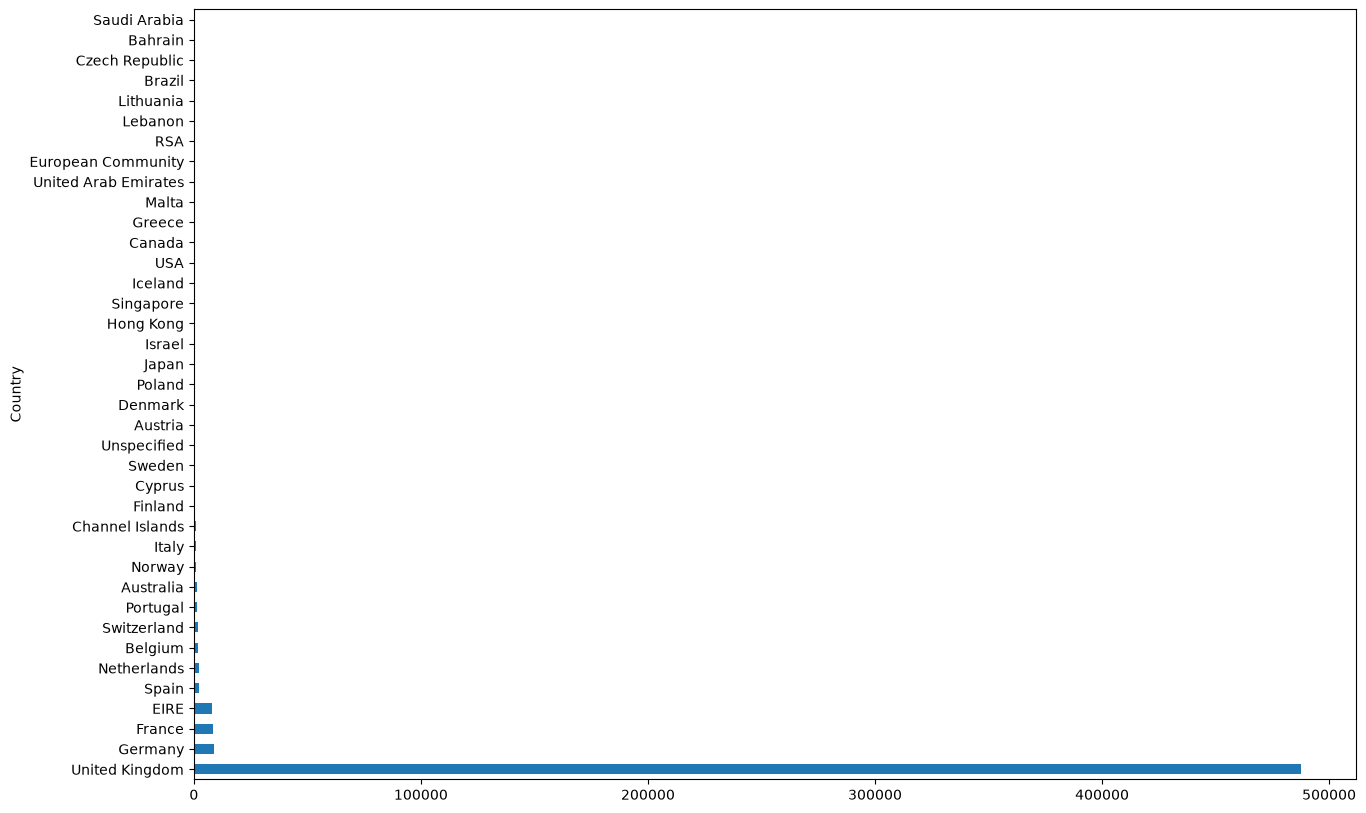

In [19]:
df['Country'].value_counts().plot(kind='barh', figsize=(15,10))

In [20]:
df['Country'].value_counts()[COUNTRY]

np.int64(9042)

Trang Kim Đạt 6451071018

## 5. Lấy hóa đơn của nước Đức và gom nhóm Quantity theo InvoiceNo, Description

In [24]:
basket = df[df['Country'] == COUNTRY].groupby(['InvoiceNo', 'Description'])['Quantity']
basket.head(10)

1109       6
1110       6
1111      12
1112      12
1113      12
          ..
541801    12
541802    12
541803    12
541804    12
541805    10
Name: Quantity, Length: 9042, dtype: int64

Trang Kim Đạt 6451071018

## 6. Chuyển về dạng hot encoding, mỗi dòng là một hóa đơn

In [25]:
basket = basket.sum().unstack().reset_index().fillna(0).set_index('InvoiceNo')
basket.head(10)

Description,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 IVORY ROSE PEG PLACE SETTINGS,12 MESSAGE CARDS WITH ENVELOPES,12 PENCIL SMALL TUBE WOODLAND,12 PENCILS SMALL TUBE RED RETROSPOT,12 PENCILS SMALL TUBE SKULL,12 PENCILS TALL TUBE POSY,12 PENCILS TALL TUBE RED RETROSPOT,12 PENCILS TALL TUBE SKULLS,...,YULETIDE IMAGES GIFT WRAP SET,ZINC HEART T-LIGHT HOLDER,ZINC STAR T-LIGHT HOLDER,ZINC BOX SIGN HOME,ZINC FOLKART SLEIGH BELLS,ZINC HEART LATTICE T-LIGHT HOLDER,ZINC METAL HEART DECORATION,ZINC T-LIGHT HOLDER STAR LARGE,ZINC T-LIGHT HOLDER STARS SMALL,ZINC WILLIE WINKIE CANDLE STICK
InvoiceNo,,,,,,,,,,,,,,,,,,,,,
536527,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536840,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536861,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536967,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536983,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
537197,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
537198,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
537201,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
537212,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [26]:
print('Số hóa đơn:', basket.shape[0], '| Số mặt hàng:', basket.shape[1])

Số hóa đơn: 457 | Số mặt hàng: 1695


Trang Kim Đạt 6451071018

## 7. Chuyển từ hot encoding sang one-hot encoding

In [28]:
def encode_data(datapoint):
    if datapoint <= 0:
        return 0
    if datapoint >= 1:
        return 1

# pandas >= 2.1 dùng .map (bản cũ dùng .applymap); mlxtend khuyến nghị kiểu bool
basket = basket.map(encode_data).astype(bool)
basket.head(10)

Description,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 IVORY ROSE PEG PLACE SETTINGS,12 MESSAGE CARDS WITH ENVELOPES,12 PENCIL SMALL TUBE WOODLAND,12 PENCILS SMALL TUBE RED RETROSPOT,12 PENCILS SMALL TUBE SKULL,12 PENCILS TALL TUBE POSY,12 PENCILS TALL TUBE RED RETROSPOT,12 PENCILS TALL TUBE SKULLS,...,YULETIDE IMAGES GIFT WRAP SET,ZINC HEART T-LIGHT HOLDER,ZINC STAR T-LIGHT HOLDER,ZINC BOX SIGN HOME,ZINC FOLKART SLEIGH BELLS,ZINC HEART LATTICE T-LIGHT HOLDER,ZINC METAL HEART DECORATION,ZINC T-LIGHT HOLDER STAR LARGE,ZINC T-LIGHT HOLDER STARS SMALL,ZINC WILLIE WINKIE CANDLE STICK
InvoiceNo,,,,,,,,,,,,,,,,,,,,,
536527,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
536840,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
536861,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
536967,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
536983,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
537197,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
537198,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
537201,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
537212,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


Trang Kim Đạt 6451071018

## 8. Xóa cột 'POSTAGE' (tiền cước phí)

In [41]:
basket = basket.drop(
    'POSTAGE',
    axis=1,
    errors='ignore'
)
basket.head(10)

Description,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 IVORY ROSE PEG PLACE SETTINGS,12 MESSAGE CARDS WITH ENVELOPES,12 PENCIL SMALL TUBE WOODLAND,12 PENCILS SMALL TUBE RED RETROSPOT,12 PENCILS SMALL TUBE SKULL,12 PENCILS TALL TUBE POSY,12 PENCILS TALL TUBE RED RETROSPOT,12 PENCILS TALL TUBE SKULLS,...,YULETIDE IMAGES GIFT WRAP SET,ZINC HEART T-LIGHT HOLDER,ZINC STAR T-LIGHT HOLDER,ZINC BOX SIGN HOME,ZINC FOLKART SLEIGH BELLS,ZINC HEART LATTICE T-LIGHT HOLDER,ZINC METAL HEART DECORATION,ZINC T-LIGHT HOLDER STAR LARGE,ZINC T-LIGHT HOLDER STARS SMALL,ZINC WILLIE WINKIE CANDLE STICK
InvoiceNo,,,,,,,,,,,,,,,,,,,,,
536527,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
536840,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
536861,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
536967,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
536983,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
537197,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
537198,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
537201,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
537212,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


Trang Kim Đạt 6451071018

## 9. Tìm tập phổ biến bằng Apriori với min_sup = 5%

In [31]:
start = time.time()
itemsets = apriori(basket, min_support=MIN_SUP, use_colnames=True)
time_apriori = time.time() - start

print('Số tập phổ biến:', len(itemsets), '| Thời gian:', round(time_apriori, 4), 'giây')
itemsets.sort_values('support', ascending=False).head(10)

Số tập phổ biến: 59 | Thời gian: 0.0122 giây


,support,itemsets
35,0.245077,frozenset({ROUND SNACK BOXES SET OF4 WOODLAND})
34,0.157549,frozenset({ROUND SNACK BOXES SET OF 4 FRUITS})
24,0.137856,frozenset({PLASTERS IN TIN WOODLAND ANIMALS})
31,0.137856,frozenset({REGENCY CAKESTAND 3 TIER})
56,0.131291,"frozenset({ROUND SNACK BOXES SET OF 4 FRUITS, ..."
48,0.126915,frozenset({WOODLAND CHARLOTTE BAG})
21,0.115974,frozenset({PLASTERS IN TIN CIRCUS PARADE})
22,0.107221,frozenset({PLASTERS IN TIN SPACEBOY})
0,0.102845,frozenset({6 RIBBONS RUSTIC CHARM})
44,0.102845,frozenset({SPACEBOY LUNCH BOX})


Trang Kim Đạt 6451071018

## 10. Tạo luật kết hợp với min_conf = 50%

In [32]:
rules = association_rules(itemsets, metric="confidence", min_threshold=MIN_CONF)
rules = rules.sort_values('confidence', ascending=False).reset_index(drop=True)
rules.info()

<class 'pandas.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   antecedents         8 non-null      object 
 1   consequents         8 non-null      object 
 2   antecedent support  8 non-null      float64
 3   consequent support  8 non-null      float64
 4   support             8 non-null      float64
 5   confidence          8 non-null      float64
 6   lift                8 non-null      float64
 7   representativity    8 non-null      float64
 8   leverage            8 non-null      float64
 9   conviction          8 non-null      float64
 10  zhangs_metric       8 non-null      float64
 11  jaccard             8 non-null      float64
 12  certainty           8 non-null      float64
 13  kulczynski          8 non-null      float64
dtypes: float64(12), object(2)
memory usage: 1.0+ KB


Trang Kim Đạt 6451071018

Chuyển vế trái, vế phải từ frozenset về chuỗi (nối tất cả các mặt hàng, không chỉ lấy mặt hàng đầu tiên).

In [33]:
rules["antecedents"] = rules["antecedents"].apply(lambda x: ', '.join(sorted(x)))
rules["consequents"] = rules["consequents"].apply(lambda x: ', '.join(sorted(x)))

In [34]:
for i in range(len(rules)):
    print(rules.loc[i, 'antecedents'],' ==> ', rules.loc[i, 'consequents'],
          ' [', round(rules.loc[i, 'support'], 4), ', ', round(rules.loc[i, 'confidence'], 4), ']')

RED RETROSPOT CHARLOTTE BAG  ==>  WOODLAND CHARLOTTE BAG  [ 0.0591 ,  0.8438 ]
ROUND SNACK BOXES SET OF 4 FRUITS  ==>  ROUND SNACK BOXES SET OF4 WOODLAND  [ 0.1313 ,  0.8333 ]
SPACEBOY LUNCH BOX  ==>  ROUND SNACK BOXES SET OF4 WOODLAND  [ 0.07 ,  0.6809 ]
PLASTERS IN TIN CIRCUS PARADE  ==>  PLASTERS IN TIN WOODLAND ANIMALS  [ 0.0678 ,  0.5849 ]
PLASTERS IN TIN SPACEBOY  ==>  PLASTERS IN TIN WOODLAND ANIMALS  [ 0.0613 ,  0.5714 ]
PLASTERS IN TIN WOODLAND ANIMALS  ==>  ROUND SNACK BOXES SET OF4 WOODLAND  [ 0.0744 ,  0.5397 ]
ROUND SNACK BOXES SET OF4 WOODLAND  ==>  ROUND SNACK BOXES SET OF 4 FRUITS  [ 0.1313 ,  0.5357 ]
WOODLAND CHARLOTTE BAG  ==>  ROUND SNACK BOXES SET OF4 WOODLAND  [ 0.0635 ,  0.5 ]


Trang Kim Đạt 6451071018

## 11. Biểu diễn độ hỗ trợ và độ tin cậy lên đồ thị phân tán

<Axes: title={'center': 'Association Rules - Germany'}, xlabel='support', ylabel='confidence'>

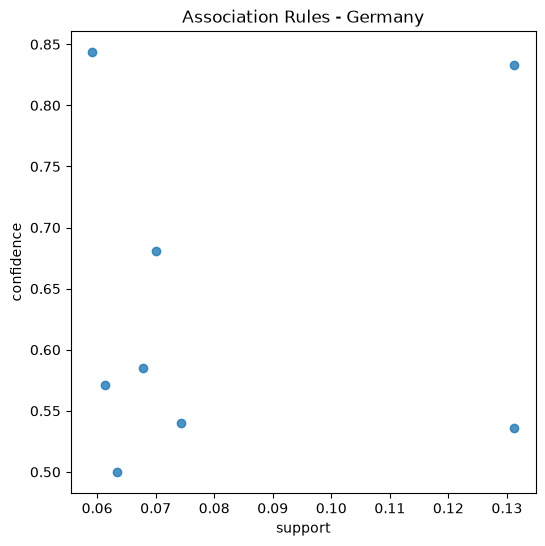

In [35]:
support=rules['support'].values
confidence=rules['confidence'].values

plt.figure(figsize=(6, 6))
plt.title('Association Rules - ' + COUNTRY)
plt.xlabel('support')
plt.ylabel('confidence')
sns.regplot(x=support, y=confidence, fit_reg=False)

Trang Kim Đạt 6451071018

## 12. FP-Growth với min_sup = 5%, min_conf = 50% và so sánh với Apriori

In [36]:
start = time.time()
itemsets_fp = fpgrowth(basket, min_support=MIN_SUP, use_colnames=True)
time_fp = time.time() - start

rules_fp = association_rules(itemsets_fp, metric="confidence", min_threshold=MIN_CONF)
print('Số tập phổ biến:', len(itemsets_fp), '| Số luật:', len(rules_fp),
      '| Thời gian:', round(time_fp, 4), 'giây')

Số tập phổ biến: 59 | Số luật: 8 | Thời gian: 0.0186 giây


In [37]:
# So sánh kết quả hai thuật toán
same_itemsets = set(itemsets['itemsets']) == set(itemsets_fp['itemsets'])
same_rules = len(rules) == len(rules_fp)

comparison = pd.DataFrame({
    'Apriori':   [len(itemsets),    len(rules),    round(time_apriori, 4)],
    'FP-Growth': [len(itemsets_fp), len(rules_fp), round(time_fp, 4)],
}, index=['Số tập phổ biến', 'Số luật', 'Thời gian (giây)'])

print('Tập phổ biến giống nhau:', same_itemsets)
print('Số luật giống nhau     :', same_rules)
comparison

Tập phổ biến giống nhau: True
Số luật giống nhau     : True


,Apriori,FP-Growth
Số tập phổ biến,59.0000,59.0000
Số luật,8.0000,8.0000
Thời gian (giây),0.0122,0.0186


Trang Kim Đạt 6451071018

**Nhận xét:** Hai thuật toán cho ra cùng một tập phổ biến và cùng số luật kết hợp, vì cả hai đều tìm *tất cả* tập phổ biến thỏa min_sup.
Khác biệt nằm ở cách làm: Apriori sinh tập ứng viên và quét dữ liệu nhiều lần, còn FP-Growth nén dữ liệu vào cây FP và không sinh ứng viên, nên thường chạy nhanh hơn khi dữ liệu lớn hoặc min_sup nhỏ.
Với dữ liệu nước Đức (số hóa đơn ít) và min_sup = 5%, chênh lệch thời gian giữa hai thuật toán là nhỏ.